# **UTS GRAF SAINS DATA**
**Rizqi Aqilah Cahayani Yuniarto - 24031554087**
- **P1 = 30 May - 7 June 2015**
- **P2 = 8-16 June 2015**

## **1. Preliminary**

### **1.1 Set up n Get to know the environment**

In [1]:
import os
import sys
import random
import zipfile
import getpass

import numpy as np
import pandas as pd
import requests
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize

import neo4j
from neo4j import GraphDatabase, RoutingControl

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python version:", sys.version.split()[0])
print("neo4j driver version:", neo4j.__version__)
print("pandas version:", pd.__version__)

Python version: 3.10.20
neo4j driver version: 6.4.1
pandas version: 2.3.3


### **1.2 Connecting to Neo4J**

In [2]:
neo4j_uri = "neo4j://127.0.0.1:7687"
username = "neo4j"
database_name = "neo4j"
password = os.environ.get("NEO4J_PASSWORD") or getpass.getpass("Neo4j password: ")

driver = GraphDatabase.driver(neo4j_uri, auth=(username, password))
try:
    driver.verify_connectivity()
    print("Connection okay")
except Exception as error:
    print(f"Failed to connect to the database: {error}")
    raise


def run_query(query, **params):
    records, _, _ = driver.execute_query(
        query, parameters_=params, database_=database_name
    )
    return pd.DataFrame([row.data() for row in records])

Connection okay


In [3]:
def add_friend(name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=database_name,
    )


def print_friends(name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=database_name, routing_=RoutingControl.READ,
    )
    for row in records:
        print(row["friend.name"])


for friend_name in ["Guinevere", "Lancelot", "Merlin"]:
    add_friend("Arthur", friend_name)
print_friends("Arthur")

# clean up only the demo nodes.
driver.execute_query("MATCH (n:Person) DETACH DELETE n", database_=database_name)
print("Demo nodes removed.")

Guinevere
Lancelot
Merlin
Demo nodes removed.


### Answers to Introductory Questions (Checkpoints)

1. **Name of the database used:** `neo4j`, which is the default Neo4j database.
2. **Other ways to access different databases within a single instance:**
   - Via the driver: change the `database_=“namadb”` parameter in `execute_query` or use `driver.session(database=“namadb”)`.
   - Via Cypher: `USE namadb MATCH ...` or `:use namadb` in the Neo4j Browser.
   - DDL commands for managing databases: `CREATE DATABASE namadb`, `SHOW DATABASES`, `DROP DATABASE namadb`. These commands are executed on the `system` database.
   - Note: Having multiple user databases in a single instance generally requires the Enterprise edition.
3. **Type of friendship graph:** A directed graph because the `-[:KNOWS]->` relationship is directed, unweighted, and simple (one node type, `Person`, and one relationship type, `KNOWS`). Since `MERGE` is used, there are no duplicate relationships or nodes.


### **1.3 Import Data RetailRocket to Neo4j**

In [4]:
data_dir = "data"
raw_csv_path = f"{data_dir}/events.csv"
zip_path = f"{data_dir}/ecommerce-dataset.zip"
dataset_url = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"

os.makedirs(data_dir, exist_ok=True)

if os.path.exists(raw_csv_path):
    print("events.csv already exists, skipping download.")
else:
    print("Downloading dataset...")
    with requests.get(dataset_url, stream=True, timeout=60) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("content-length", 0))
        with open(zip_path, "wb") as file, tqdm(
            total=total_bytes, unit="B", unit_scale=True, desc="Download"
        ) as progress_bar:
            for chunk in response.iter_content(chunk_size=1 << 20):
                file.write(chunk)
                progress_bar.update(len(chunk))
    with zipfile.ZipFile(zip_path) as archive:
        archive.extract("events.csv", data_dir)
    print("Download and extraction finished.")

events.csv already exists, skipping download.


In [5]:
raw_df = pd.read_csv(raw_csv_path)
raw_df["datetime"] = pd.to_datetime(raw_df["timestamp"], unit="ms", utc=True)

print("Total rows:", len(raw_df))
print("Time range:", raw_df["datetime"].min(), "->", raw_df["datetime"].max())
display(raw_df.head())
display(raw_df["event"].value_counts().rename("total").to_frame())

Total rows: 2756101
Time range: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00


,total
event,
view,2664312
addtocart,69332
transaction,22457


## **2. UTS Question**

### **2.1 Wrangling n EDA**

#### No. 1 - Setting Two Periods

Based on the class int24 distribution, I used the dates May 30-June 7, 2015, for P1. And June 8-16, 2015, for P2.
Two time periods are used as filters on the `timestamp` column. Since the `timestamp` is in **milliseconds**, it is converted using `unit=“ms”`. The time zone used is **UTC**. The end date is exclusive, so P1 covers May 30 at 00:00 through June 7 at 23:59:59.

In [6]:
# P1: 30 May - 7 June 2015 | P2: 8 June - 16 June 2015
periods = {
    "P1": ("2015-05-30", "2015-06-08"), # training, end date exclusive
    "P2": ("2015-06-08", "2015-06-17"), # testing, end date exclusive
}

period_chunks = []
for period_name, (start_date, end_date) in periods.items():
    part = raw_df[
        (raw_df["datetime"] >= start_date) & (raw_df["datetime"] < end_date)
    ].assign(period=period_name)
    period_chunks.append(part)
    print(f"{period_name}: {start_date} until {end_date} (exclusive), rows: {len(part)}")

filtered_df = pd.concat(period_chunks).drop(columns="datetime")
period_summary = filtered_df.groupby(["period", "event"]).size().unstack(fill_value=0)
display(period_summary)

P1: 2015-05-30 until 2015-06-08 (exclusive), rows: 178872
P2: 2015-06-08 until 2015-06-17 (exclusive), rows: 178785


event,addtocart,transaction,view
period,,,
P1,4206,1389,173277
P2,4505,1433,172847


#### No.2 - Save to CSV


In [7]:
filtered_csv_path = f"{data_dir}/events_filtered.csv"
filtered_df.to_csv(filtered_csv_path, index=False)
print("Saved to:", filtered_csv_path)
print("Total rows saved:", len(filtered_df))

Saved to: data/events_filtered.csv
Total rows saved: 357657


In [30]:
df_filtered = pd.read_csv("data/events_filtered.csv")
for period_name in ["P1", "P2"]:
    part = df_filtered[df_filtered["period"] == period_name]
    part.to_csv(f"data/events_{period_name.lower()}.csv", index=False)
    print(period_name, "rows:", len(part))

P1 rows: 178872
P2 rows: 178785


##### Importing into Neo4j (Step 1.3, No. 3-5, using the filtered data)

The import is performed in batches using `UNWIND`. Differences from the sample code in the problem:
- The source is `events_filtered.csv`, and each relation is assigned a `period` property (P1/P2) so that the training and testing data can be separated in the graph.
- Rows are grouped by event type, and each group uses a single `CREATE` query. The result is the same as the `CALL { ... UNION ALL ... }` version, but it’s more efficient.
- `create_constraints` is created here to ensure that `MERGE` runs quickly and there are no duplicate nodes.
- The import process only runs if the graph is still empty, so it’s safe to rerun.

In [8]:
batch_size = 10000
reimport = False 

import_queries = {
    "view": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
    """,
    "addtocart": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
    """,
    "transaction": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                             transactionId: row.transactionid}]->(i)
    """,
}


def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_unique IF NOT EXISTS "
             "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_unique IF NOT EXISTS "
             "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")


def import_batch(tx, batch):
    by_event = {}
    for row in batch:
        by_event.setdefault(row["event"], []).append(row)
    for event_type, rows in by_event.items():
        tx.run(import_queries[event_type], batch=rows)


existing_relationships = int(run_query("MATCH ()-[r]->() RETURN count(r) AS total").loc[0, "total"])

if reimport and existing_relationships > 0:
    print("Wiping existing data...")
    driver.execute_query("MATCH (n) DETACH DELETE n", database_=database_name)
    existing_relationships = 0

if existing_relationships > 0:
    print(f"Graph already contains {existing_relationships} relationships, skipping import.")
else:
    total_rows = len(pd.read_csv(filtered_csv_path, usecols=["event"]))
    total_batches = (total_rows // batch_size) + 1
    with driver.session(database=database_name) as session:
        create_constraints(session)
        print(f"Reading data from: {filtered_csv_path}")
        print("Starting import into Neo4j...")
        for chunk in tqdm(
            pd.read_csv(filtered_csv_path, chunksize=batch_size),
            total=total_batches, desc="Importing batches",
        ):
            chunk["transactionid"] = chunk["transactionid"].apply(
                lambda value: "" if pd.isna(value) else str(int(value))
            )
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    print("Import finished.")

Graph already contains 452730 relationships, skipping import.


#### No.3 - Subgraph Composition

The query is executed via the Python API (`driver.execute_query`). Cypher explanation:
- `MATCH (n)` retrieves all nodes in the graph.
- `labels(n)[0]` retrieves the first label (node type) of each node, which is either `Visitor` or `Item`.
- `count(*)` counts the number of rows per group. Cypher automatically groups by non-aggregate columns (in this case, the node label).
- `MATCH ()-[r]->()` retrieves all directed relationships regardless of the end nodes.
- `type(r)` is the relationship type name (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`), and `r.period` is the property that distinguishes P1 from P2.
- `ORDER BY` sorts the results for readability.


In [9]:
node_composition = run_query("""
    MATCH (n)
    RETURN labels(n)[0] AS node_type, count(*) AS total
    ORDER BY total DESC
""")
relationship_composition = run_query("""
    MATCH ()-[r]->()
    RETURN type(r) AS relationship_type, r.period AS period, count(*) AS total
    ORDER BY relationship_type, period
""")
display(node_composition)
display(relationship_composition)

graph_relationship_total = int(relationship_composition["total"].sum())
print("Total relationships in graph:", graph_relationship_total)
print("Rows in filtered CSV:", len(filtered_df))
print("Match:", graph_relationship_total == len(filtered_df))

,node_type,total
0,Visitor,189433
1,Item,87970


,relationship_type,period,total
0,ADDED_TO_CART,P1,4206
1,ADDED_TO_CART,P2,4505
2,BOUGHT,P1,1389
3,BOUGHT,P2,1433
4,SIMILAR_TO,None,95073
5,VIEWED,P1,173277
6,VIEWED,P2,172847


Total relationships in graph: 452730
Rows in filtered CSV: 357657
Match: False


**Interpretation.** The resulting subgraph is a **directed bipartite graph** with two types of nodes: `Visitor` (189,433) and `Item` (87,970). All edges (357,657) flow from `Visitor` to `Item`, and their total number matches the number of rows in the filtered CSV, so there is no missing or duplicate data. The composition of the relationships is highly skewed: `VIEWED` accounts for about 96.8%, `ADDED_TO_CART` for about 2.4%, and `BOUGHT` for only about 0.8%. This means that purchase signals are very rare, so recommendations need to use all three types of interactions with different weights (not just purchases).

#### No. 4 - Vector Space Modeling (VSM) for User Nodes

Only **P1** data is used (training fold). Each `Visitor` is represented as a single vector, whose dimensions correspond to all `Items`. The value of each cell is the interaction weight: `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5. If a user-item pair has multiple interactions, the weights are summed.

In [10]:
interactions_p1 = run_query("""
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    WHERE r.period = 'P1'
    RETURN v.visitorId AS visitor, i.itemId AS item, type(r) AS event_type
""")

event_weights = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
interactions_p1["weight"] = interactions_p1["event_type"].map(event_weights)

pairs_p1 = interactions_p1.groupby(["visitor", "item"], as_index=False)["weight"].sum()
print(len(interactions_p1), "interactions =", len(pairs_p1), "unique user-item pairs")
display(pairs_p1.head())

178872 interactions = 140352 unique user-item pairs


,visitor,item,weight
0,8,434230,1
1,17,138434,1
2,23,44608,1
3,28,295343,1
4,52,108504,1


In [11]:
visitor_categories = pairs_p1["visitor"].astype("category")
item_categories = pairs_p1["item"].astype("category")

visitor_ids = visitor_categories.cat.categories.to_numpy() # row index = visitorId
item_ids = item_categories.cat.categories.to_numpy() # column index = itemId

X = sparse.csr_matrix(
    (pairs_p1["weight"].to_numpy(),(visitor_categories.cat.codes.to_numpy(), item_categories.cat.codes.to_numpy()),),
    shape=(len(visitor_ids), len(item_ids)),)


def describe_matrix(matrix, name):
    total_cells = matrix.shape[0] * matrix.shape[1]
    print(f"{name}")
    print(f"shape: {matrix.shape}")
    print(f"nonzero: {matrix.nnz}")
    print(f"sparsity: {100 * (1 - matrix.nnz / total_cells):.4f}%")
    nonzero_per_row = pd.Series(matrix.getnnz(axis=1))
    print("nonzero per row (min / mean / median / max):",
          nonzero_per_row.min(), "/", round(nonzero_per_row.mean(), 2), "/",
          nonzero_per_row.median(), "/", nonzero_per_row.max())


describe_matrix(X, "User VSM (rows = users, dimensions = items)")

User VSM (rows = users, dimensions = items)
shape: (97070, 57601)
nonzero: 140352
sparsity: 99.9975%
nonzero per row (min / mean / median / max): 1 / 1.45 / 1.0 / 465


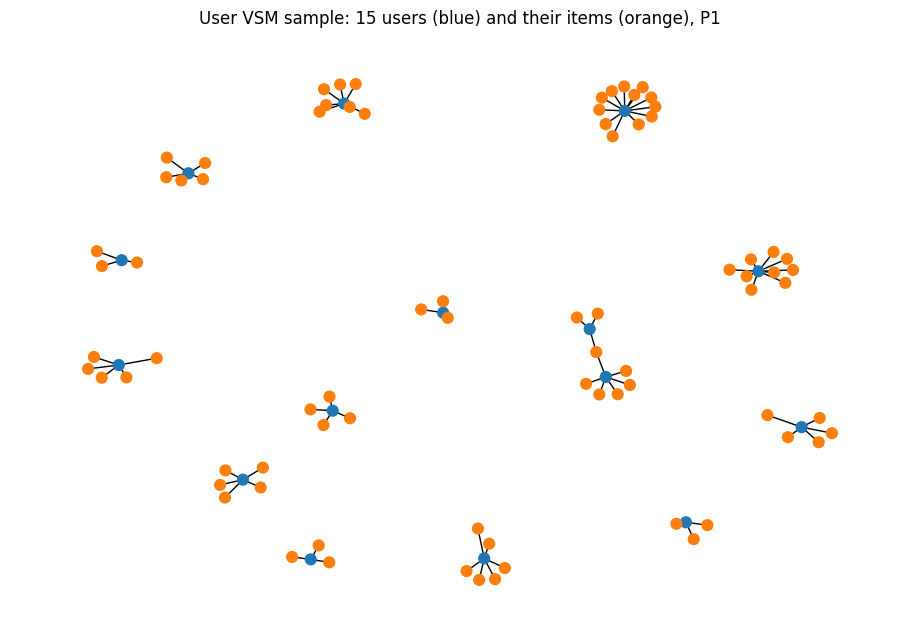

Nodes in sample: 93 | Edges in sample: 79


In [12]:
def plot_bipartite(pairs, center_column, title, n_centers=15, min_neighbors=3):
    other_column = "item" if center_column == "visitor" else "visitor"
    neighbor_counts = pairs.groupby(center_column)[other_column].transform("count")
    candidates = pairs.loc[neighbor_counts >= min_neighbors, center_column].unique()
    selected = random.Random(SEED).sample(list(candidates), min(n_centers, len(candidates)))
    sample = pairs[pairs[center_column].isin(selected)]

    graph = nx.Graph()
    for row in sample.itertuples(index=False):
        graph.add_edge(f"U{row.visitor}", f"I{row.item}", weight=row.weight)

    colors = ["tab:blue" if node.startswith("U") else "tab:orange" for node in graph.nodes]
    pos = nx.spring_layout(graph, seed=SEED)

    plt.figure(figsize=(9, 6))
    nx.draw(graph, pos, node_color=colors, node_size=60, with_labels=False)
    plt.title(title)
    plt.show()
    print("Nodes in sample:", graph.number_of_nodes(), "| Edges in sample:", graph.number_of_edges())


plot_bipartite(
    pairs_p1, "visitor",
    "User VSM sample: 15 users (blue) and their items (orange), P1",
)

**Interpretation.** The user-item matrix is **97,070 rows by 57,601 columns** (vector dimension = number of items) with only **140,352 filled cells**, resulting in a sparsity of **99.9975%**. On average, each user interacts with only about **1.45 items**, so each user’s vector is very short and almost all of its dimensions are zero. The NetworkX plot shows the same thing: each user (blue) forms a “star” with their items (orange), and these stars are **not connected to one another** because the 15 sample users do not share any items. This is not an error, but evidence that the graph is very sparse. Consequently, similarity between users can only be calculated if two users happen to view the same item.

#### No. 5 - VSM for Item Nodes

Each `Item` is represented by a single vector, whose dimensions correspond to all `Visitors`. This matrix is the **transpose** of the user-item matrix.

Item VSM (rows = items, dimensions = users)
shape: (57601, 97070)
nonzero: 140352
sparsity: 99.9975%
nonzero per row (min / mean / median / max): 1 / 2.44 / 1.0 / 332


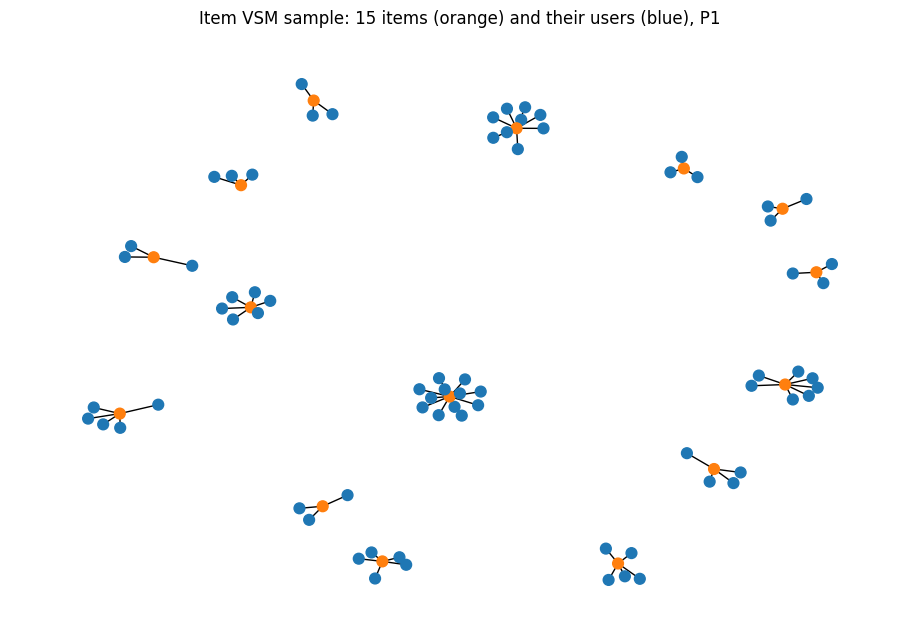

Nodes in sample: 89 | Edges in sample: 74


In [13]:
X_item = X.T.tocsr()
describe_matrix(X_item, "Item VSM (rows = items, dimensions = users)")
plot_bipartite(pairs_p1, "item","Item VSM sample: 15 items (orange) and their users (blue), P1",)

**Interpretation.** The item-user matrix is **57,601 rows by 97,070 columns**, with nonzero values and sparsity exactly matching those of the VSM User matrix (**140,352** and **99.9975%**), since it is indeed its transpose. The difference lies in the distribution of entries per row: on average, each item is viewed by about **2.44 users**, which is more than the average number of items per user (1.45). Thus, the item vector is slightly “richer” for comparison. In the plot, items (orange) form the center of the star, and users (blue) form the points. A few popular items have many users, but most items are viewed by only one or two users.

#### No. 6 - Which projection is better between number 4 and 5?

A bipartite graph is projected into two unipartite graphs using a binary matrix `B` (1 if there is an interaction):
- **User-User** = `B @ B.T` (two users are connected if they share at least one item).
- **Item-Item** = `B.T @ B` (two items are connected if they are viewed by at least one common user).

Both are compared based on the number of nodes, edges, density, average degree, isolated nodes, connected components, and memory usage.

In [14]:
X_binary = (X > 0).astype(np.float32)
projections = {
    "User-User": (X_binary @ X_binary.T).tocsr(),
    "Item-Item": (X_binary.T @ X_binary).tocsr(),
}

projection_rows = []
for projection_name, matrix in projections.items():
    n_nodes = matrix.shape[0]
    degree = matrix.getnnz(axis=1) - 1  # minus the self-loop on the diagonal
    n_edges = int(degree.sum() // 2)
    n_components, component_labels = connected_components(matrix, directed=False)
    component_sizes = np.bincount(component_labels)
    projection_rows.append({
        "projection": projection_name,
        "nodes": n_nodes,
        "edges": n_edges,
        "density": n_edges / (n_nodes * (n_nodes - 1) / 2),
        "avg_degree": round(float(degree.mean()), 2),
        "isolated_nodes": int((degree == 0).sum()),
        "components": int(n_components),
        "largest_component": int(component_sizes.max()),
        "memory_MB": round((matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1e6, 1),
    })

projection_comparison = pd.DataFrame(projection_rows).set_index("projection")
display(projection_comparison)

,nodes,edges,density,avg_degree,isolated_nodes,components,largest_component,memory_MB
projection,,,,,,,,
User-User,97070,604947,0.000128,12.46,23971,32255,47301,10.8
Item-Item,57601,546370,0.000329,18.97,29487,32255,20961,9.4


**Conclusion:** The Item-Item projection is the better choice overall (more efficient, with more similarity signal per node), with one caveat.
1. **More efficient:** Item-Item has 57,601 nodes vs 97,070 (about 41% fewer), fewer edges (546,370 vs 604,947), and lower memory (9.4 MB vs 10.8 MB), so pairwise similarity calculations are cheaper.
2. **More signal per node:** density is about 2.6 times higher (0.000329 vs 0.000128) and the average degree is higher (18.97 vs 12.46).
3. **More stable:** the item catalog stays relatively constant between P1 and P2, whereas many users in P2 are new and have no history in P1.

**Caveat / trade-off:** Item-Item has proportionally more isolated nodes (29,487, or 51.2% of items, vs 23,971, or 24.7% of users) and a smaller largest component (20,961 nodes, 36.4%, vs 47,301 nodes, 48.7%). Many items are seen by only one visitor who saw nothing else. Both projections have the same number of connected components (32,255) because they come from the same bipartite graph. User-User remains useful for personalised recommendations, which is why it is used for KNN in section 2.2. For the similarity calculation in Neo4j (no. 7), Item-Item was chosen.

#### No.7 - Similarity Calculation

Flow:
1. Select a reference record (one `Item`) at random but in a reproducible manner from among items that have enough neighbors.
2. **Before:** Ensure there are no existing `SIMILAR_TO` relationships, then display the graph around the reference item.
3. Create a projection in GDS memory (Item = Visitor, P1 data only, unique pairs), then calculate node similarity (Jaccard) with `topK = 5`.
4. **After:** Write the results back to the graph as a `(:Item)-[:SIMILAR_TO {score}]->(:Item)` relationship, then display it again.

Jaccard similarity between two items = the number of users who viewed both divided by the number of users who viewed at least one of them. The value ranges from 0 to 1.

In [15]:
visitors_per_item = np.asarray(X_binary.sum(axis=0)).ravel()
item_degree = projections["Item-Item"].getnnz(axis=1) - 1

# reference item: seen by 5-15 users and sharing users with at least 5 other items
candidate_indices = np.where(
    (visitors_per_item >= 5)
    & (visitors_per_item <= 15)
    & (item_degree >= 5)
)[0]
if len(candidate_indices) == 0:
    candidate_indices = np.where(item_degree >= 5)[0]

reference_index = int(random.Random(SEED).choice(list(candidate_indices)))
reference_id = int(item_ids[reference_index])
print("Number of candidate reference items:", len(candidate_indices))
print("Reference item (itemId):", reference_id)
print("Users who interacted with it (P1):", int(visitors_per_item[reference_index]))
print("Items sharing at least one user with it:", int(item_degree[reference_index]))

Number of candidate reference items: 3781
Reference item (itemId): 324537
Users who interacted with it (P1): 5
Items sharing at least one user with it: 26


In [16]:
def get_reference_subgraph(reference_item_id, max_items_per_visitor=20):
    edges = run_query("""
        MATCH (a:Item {itemId: $id})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
        WHERE r1.period = 'P1'
        WITH DISTINCT a, v
        MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
        WHERE r2.period = 'P1'
        RETURN DISTINCT v.visitorId AS visitor, b.itemId AS item
    """, id=reference_item_id)
    item_counts = edges.groupby("visitor")["item"].transform("count")
    return edges[(item_counts <= max_items_per_visitor) | (edges["item"] == reference_item_id)]


def plot_subgraph(interaction_edges, reference_item_id, similarity=None, title=""):
    graph = nx.Graph()
    for row in interaction_edges.itertuples(index=False):
        graph.add_edge(f"U{row.visitor}", f"I{row.item}")
    interaction_edge_list = list(graph.edges())

    similarity_edges = []
    if similarity is not None:
        for row in similarity.itertuples(index=False):
            similarity_edges.append((f"I{row.reference_item}", f"I{row.similar_item}", float(row.score)))
            graph.add_edge(f"I{row.reference_item}", f"I{row.similar_item}")

    reference_node = f"I{reference_item_id}"
    similar_nodes = {pairs[1] for pairs in similarity_edges}
    visitor_nodes = [s for s in graph.nodes if s.startswith("U")]
    item_nodes = [s for s in graph.nodes if s.startswith("I") and s != reference_node]
    pos = nx.spring_layout(graph, seed=SEED)

    plt.figure(figsize=(10, 7))
    nx.draw_networkx_edges(graph, pos, edgelist=interaction_edge_list, alpha=0.4)
    nx.draw_networkx_nodes(graph, pos, nodelist=visitor_nodes, node_color="tab:blue", node_size=60)
    nx.draw_networkx_nodes(graph, pos, nodelist=item_nodes, node_color="tab:orange", node_size=60)
    nx.draw_networkx_nodes(graph, pos, nodelist=[reference_node], node_color="tab:red", node_size=250)
    if similarity_edges:
        nx.draw_networkx_edges(graph, pos, edgelist=[(a, b) for a, b, _ in similarity_edges],edge_color="red", style="dashed", width=2,)
        nx.draw_networkx_edge_labels(graph, pos, edge_labels={(a, b): f"{score:.3f}" for a, b, score in similarity_edges}, font_size=8,)
        nx.draw_networkx_labels(graph, pos, labels={s: s for s in similar_nodes | {reference_node}}, font_size=7)
    plt.title(title + "\n(red = reference item, orange = other items, blue = visitors)")
    plt.axis("off")
    plt.show()
    print("Nodes:", graph.number_of_nodes(), "| Edges:", graph.number_of_edges())

Before Similarity Calculation

SIMILAR_TO relationships BEFORE: 0


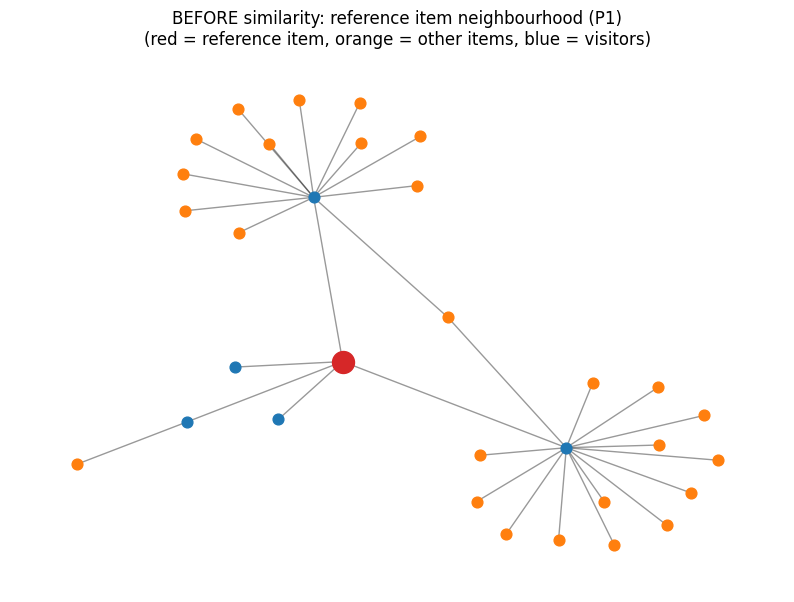

Nodes: 32 | Edges: 32


In [17]:
run_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s")

before = run_query("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS similar_to_count")
print("SIMILAR_TO relationships BEFORE:", int(before.loc[0, "similar_to_count"]))

reference_subgraph = get_reference_subgraph(reference_id)
plot_subgraph(reference_subgraph, reference_id, title="BEFORE similarity: reference item neighbourhood (P1)")

Create a projection in GDS memory

In [18]:
driver.execute_query("CALL gds.graph.drop('item_graph_p1', false)", database_=database_name)

gds_projection = run_query("""
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    WHERE r.period = 'P1'
    WITH DISTINCT i, v
    WITH gds.graph.project('item_graph_p1', i, v) AS g
    RETURN g.graphName AS graph_name, g.nodeCount AS n_nodes, g.relationshipCount AS relationship_count
""")
display(gds_projection)

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. `schema` returned by the procedure `gds.graph.drop` is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('item_graph_p1', false)"


,graph_name,n_nodes,relationship_count
0,item_graph_p1,154671,140352


In [19]:
similarity_result = run_query("""
    CALL gds.nodeSimilarity.write('item_graph_p1', {
        topK: 5,
        writeRelationshipType: 'SIMILAR_TO',
        writeProperty: 'score'
    })
    YIELD nodesCompared, relationshipsWritten
    RETURN nodesCompared AS nodes_compared, relationshipsWritten AS relationships_written
""")
display(similarity_result)

,nodes_compared,relationships_written
0,57601,95073


#### No.7a - The five records with the highest similarity to the reference item

In [20]:
top5_similar = run_query("""
    MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemId AS reference_item, b.itemId AS similar_item, s.score AS score
    ORDER BY score DESC, similar_item ASC
    LIMIT 5
""", id=reference_id)
display(top5_similar)

,reference_item,similar_item,score
0,324537,356452,0.25
1,324537,155664,0.20
2,324537,270270,0.20
3,324537,367947,0.20
4,324537,388984,0.20


#### No. 7b - The similarity score is written back to the graph

The similarity score has been stored in the graph as the `score` property on the `SIMILAR_TO` relationship (the `write` step above). The following query demonstrates this directly from the Neo4j graph.

In [21]:
score_summary = run_query("""
    MATCH ()-[s:SIMILAR_TO]->()
    RETURN count(s) AS relationship_count, min(s.score) AS score_min,
           avg(s.score) AS score_avg, max(s.score) AS score_max
""")
display(score_summary)

stored_in_graph = run_query("""
    MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
    RETURN a.itemId AS reference_item, type(s) AS relationship_type,
           b.itemId AS similar_item, s.score AS score
    ORDER BY score DESC, similar_item ASC
""", id=reference_id)
display(stored_in_graph)

,relationship_count,score_min,score_avg,score_max
0,95073,0.002967,0.411218,1.0


,reference_item,relationship_type,similar_item,score
0,324537,SIMILAR_TO,356452,0.25
1,324537,SIMILAR_TO,155664,0.20
2,324537,SIMILAR_TO,270270,0.20
3,324537,SIMILAR_TO,367947,0.20
4,324537,SIMILAR_TO,388984,0.20


#### No. 8 - Conditions Before and After the Similarity Calculation

The **before** graph is shown in the cell before the GDS projection. Here is the **after** graph: the same structure, plus the `SIMILAR_TO` relationship (red dashed line) from the reference item to the five most similar items, complete with their scores.

SIMILAR_TO relationships BEFORE: 0
SIMILAR_TO relationships AFTER : 95073


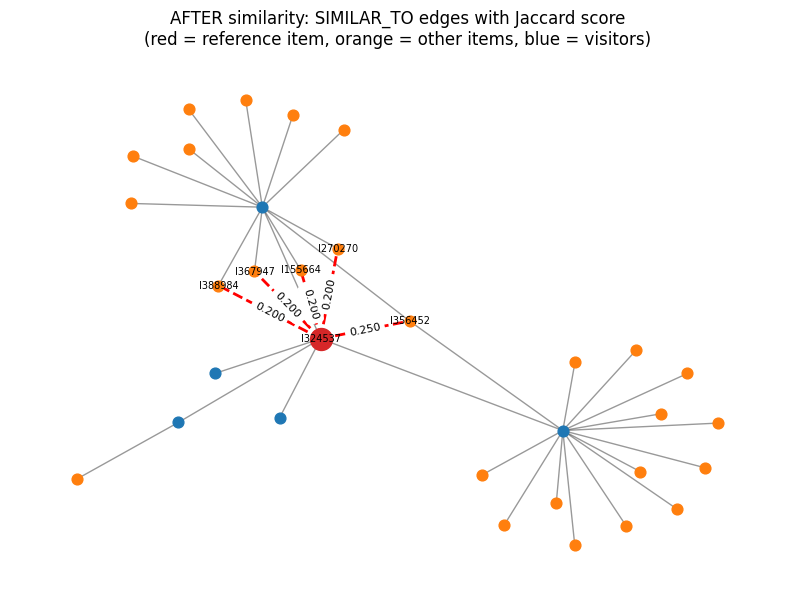

Nodes: 32 | Edges: 37


In [22]:
after = run_query("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS similar_to_count")
print("SIMILAR_TO relationships BEFORE:", int(before.loc[0, "similar_to_count"]))
print("SIMILAR_TO relationships AFTER :", int(after.loc[0, "similar_to_count"]))

plot_subgraph(reference_subgraph, reference_id, similarity=top5_similar,title="AFTER similarity: SIMILAR_TO edges with Jaccard score")

**Interpretation.** Before the calculation, the graph contained only `Visitor to Item` interaction relationships and no `SIMILAR_TO` relationships (count = 0). After running GDS node similarity, 95,073 `SIMILAR_TO` relationships were written between `Item` nodes (57,601 items compared, topK = 5). The reference item 324537, seen by 5 visitors in P1, is now linked to its 5 most similar items with Jaccard scores between 0.20 and 0.25. Scores for this item are low because the catalog is huge and each item has only a few visitors. Across the whole graph the mean score is 0.41 and the maximum is 1.0: high scores mostly occur between items seen by one and the same single visitor, so they should be interpreted with caution in such sparse data.

### **2.2 Analytics**

In this section **user-based KNN** (*user-based collaborative filtering*) is used: recommendations for a user are derived from items selected by the 5 most similar users (based on cosine similarity in the User VSM from the P1 dataset). The **P2** dataset is used as the ground truth for evaluation.

In [23]:
# check how many users appeared in both periods
interactions_p2 = run_query("""
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    WHERE r.period = 'P2'
    RETURN v.visitorId AS visitor, i.itemId AS item, type(r) AS event_type
""")

visitor_set_p1 = {int(v) for v in visitor_ids}
item_set_p1 = {int(b) for b in item_ids}
visitor_set_p2 = {int(v) for v in interactions_p2["visitor"].unique()}
item_set_p2 = {int(b) for b in interactions_p2["item"].unique()}
visitors_in_both = visitor_set_p1 & visitor_set_p2

print("P1 users:", len(visitor_set_p1), "| P2 users:", len(visitor_set_p2))
print("Users in both periods:", len(visitors_in_both))
print("P2 items that also exist in P1:", len(item_set_p1 & item_set_p2),"of", len(item_set_p2))

p2_items_per_visitor = {
    int(v): {int(b) for b in group["item"]}
    for v, group in interactions_p2.groupby("visitor")}

P1 users: 97070 | P2 users: 96848
Users in both periods: 4485
P2 items that also exist in P1: 28529 of 58898


#### No. 1a - KNN Script for Recommendations

How the `knn_recommend` function works:
1. Calculate the cosine similarity of the target user to all other users in the User VSM matrix (`X`).
2. Select the k = 5 neighbors with the highest similarity (similarity must be greater than 0).
3. Score an item = sum (neighbor’s similarity × neighbor’s interaction weight for that item).
4. Exclude items the target user has already interacted with in P1, then sort by highest score. If scores are tied, prioritize the item with the lower ID to ensure deterministic results.

In [24]:
X_normalized = normalize(X.astype(np.float64))  # L2-normalised rows, so dot product = cosine similarity
visitor_index = {int(v): n for n, v in enumerate(visitor_ids)}

def knn_recommend(target_index, k=5, n_recommendations=5):
    similarity = (X_normalized @ X_normalized[target_index].T).toarray().ravel()
    similarity[target_index] = 0  # a user is not their own neighbour

    order = np.argsort(-similarity, kind="stable")[:k]
    neighbors = order[similarity[order] > 0]
    neighbors_table = pd.DataFrame({
        "visitor": visitor_ids[neighbors],
        "similarity": similarity[neighbors],
    })
    if len(neighbors) == 0:
        return neighbors_table, pd.DataFrame(columns=["item", "score"])

    item_scores = np.asarray(X[neighbors].T @ similarity[neighbors]).ravel()
    item_scores[X[target_index].indices] = 0  # drop items the target user already touched
    candidate_items = np.where(item_scores > 0)[0]
    candidate_items = candidate_items[np.lexsort((item_ids[candidate_items], -item_scores[candidate_items]))][:n_recommendations]

    recommendations_table = pd.DataFrame({
        "item": item_ids[candidate_items],
        "score": item_scores[candidate_items],
    })
    return neighbors_table, recommendations_table

def hit_at_k(recommended, ground_truth, n=5):
    return int(any(int(b) in ground_truth for b in recommended[:n]))

def ndcg_at_k(recommended, ground_truth, n=5):
    dcg = sum(1.0 / np.log2(pos + 2)
        for pos, b in enumerate(recommended[:n]) if int(b) in ground_truth)
    idcg = sum(1.0 / np.log2(pos + 2) for pos in range(min(len(ground_truth), n)))
    return float(dcg / idcg) if idcg > 0 else 0.0

##### Random (reproducible) user selection

The process: the list of users in P1 and P2 is sorted, randomized using `random.Random(42)`, and then the first user who meets the following criteria is selected:
- has 5 neighbors with a similarity > 0 and at least 5 candidate recommendation items, and
- has at least one item in P2 that is also present in the P1 catalog (so that recommendations from P1 can be valid).

In [25]:
candidate_list = sorted(visitors_in_both)
random.Random(SEED).shuffle(candidate_list)


def is_eligible(target_id):
    ground_truth = p2_items_per_visitor[target_id]
    if not (ground_truth & item_set_p1):
        return None
    neighbors_table, recommendations_table = knn_recommend(visitor_index[target_id])
    if len(neighbors_table) == 5 and len(recommendations_table) >= 5:
        return neighbors_table, recommendations_table
    return None


selected_visitor = None
for attempt, target_id in enumerate(candidate_list, start=1):
    result = is_eligible(target_id)
    if result is not None:
        selected_visitor = target_id
        neighbors_table, recommendations_table = result
        break
    if attempt >= 20000:
        break

if selected_visitor is None:
    raise RuntimeError("No eligible user found, relax the selection criteria.")

selected_truth = p2_items_per_visitor[selected_visitor]
print(f"Random seed: {SEED}")
print(f"Selected user (visitorId): {selected_visitor} (after {attempt} candidates checked)")
print("Items in P1 for this user:", int(X[visitor_index[selected_visitor]].nnz))
print("Items in P2 (ground truth):", len(selected_truth))
print("\nTop-5 nearest neighbours (k = 5):")
display(neighbors_table)

Random seed: 42
Selected user (visitorId): 311205 (after 1 candidates checked)
Items in P1 for this user: 5
Items in P2 (ground truth): 10

Top-5 nearest neighbours (k = 5):


,visitor,similarity
0,1010759,0.583460
1,261887,0.444884
2,490807,0.404557
3,1330789,0.291730
4,1125271,0.186591


#### No. 1b - Three advertised items (k = 5)

The item with the highest score from the KNN is selected as the ad. The top 5 list is also displayed because it is used to calculate Hit@5 and NDCG@5.

In [26]:
print("Top-5 recommendations:")
display(recommendations_table)

ad_items = recommendations_table.head(3)
print("3 items to advertise to user", selected_visitor, ":")
display(ad_items)

Top-5 recommendations:


,item,score
0,279869,1.334652
1,389550,1.253997
2,59405,0.889768
3,239333,0.889768
4,455570,0.889768


3 items to advertise to user 311205 :


,item,score
0,279869,1.334652
1,389550,1.253997
2,59405,0.889768


#### No. 2 - Evaluation: Hit@5 and NDCG@5

The ground truth consists of all items that the user clicked on in **P2**. The formulas used are:

- **Hit@5** = 1 if at least one of the 5 recommended items is in the ground truth; otherwise, 0.
- **DCG@5** = the sum of `rel_i / log2(i + 1)` for positions `i = 1..5`, where `rel_i = 1` if the item at position `i` is in the ground truth.
- **NDCG@5** = DCG@5 divided by the ideal DCG (all relevant items placed at the top positions).

In [27]:
top5_list = list(recommendations_table["item"])
hit_5 = hit_at_k(top5_list, selected_truth, n=5)
ndcg_5 = ndcg_at_k(top5_list, selected_truth, n=5)

print("Recommended top-5:", [int(b) for b in top5_list])
print("Ground truth (P2):", sorted(selected_truth)[:20], "..." if len(selected_truth) > 20 else "")
print("Items hit:", [int(b) for b in top5_list if int(b) in selected_truth])
print(f"Hit@5 = {hit_5}")
print(f"NDCG@5 = {ndcg_5:.4f}")

if hit_5 == 1:
    print("Interpretation: at least one recommended item was really touched by the user in P2.")
else:
    print("Interpretation: none of the 5 recommended items appeared in the user's P2 activity.")

Recommended top-5: [279869, 389550, 59405, 239333, 455570]
Ground truth (P2): [47174, 175751, 182131, 224184, 332018, 344388, 361956, 362867, 397841, 437490] 
Items hit: []
Hit@5 = 0
NDCG@5 = 0.0000
Interpretation: none of the 5 recommended items appeared in the user's P2 activity.


#### Additional evaluation: average across many users

Hit@5 and NDCG@5 for a single user are only 0 or 1 (or simple fractions), so they are highly subject to chance. For comparison, the same metrics are calculated for up to 300 other users who meet the same criteria (random order with the same seed).

In [28]:
eval_rows = []
for attempt, target_id in enumerate(candidate_list, start=1):
    result = is_eligible(target_id)
    if result is not None:
        _, rec_table = result
        top5 = list(rec_table["item"])
        ground_truth = p2_items_per_visitor[target_id]
        eval_rows.append({
            "visitor": target_id,
            "hit_5": hit_at_k(top5, ground_truth),
            "ndcg_5": ndcg_at_k(top5, ground_truth),
        })
    if len(eval_rows) >= 300 or attempt >= 20000:
        break

multi_user_eval = pd.DataFrame(eval_rows)
print("Users evaluated:", len(multi_user_eval))
print(f"Mean Hit@5: {multi_user_eval['hit_5'].mean():.4f}")
print(f"Mean NDCG@5: {multi_user_eval['ndcg_5'].mean():.4f}")

Users evaluated: 300
Mean Hit@5: 0.0833
Mean NDCG@5: 0.0298


**Interpretation.** For the randomly selected user (visitorId 311205, seed 42), none of the 5 recommended items appeared in the user's P2 activity, so Hit@5 = 0 and NDCG@5 = 0. Across 300 eligible users, the mean Hit@5 is 0.0833 (about 8% of users received at least one correct item in the top 5) and the mean NDCG@5 is 0.0298. Low values are expected with this dataset: (1) the periods are only about 8-9 days, so user histories are very short (about 1.45 items on average); (2) the catalog is very large, so the chance that five recommendations match the items a user touches in P2 is small; (3) the ground truth includes all event types, mostly `view`, which tend to be noisy, while purchases are very rare. Possible improvements: a longer training period, only using users with richer histories, or adding an item popularity signal.

## Closing

In [29]:
driver.execute_query("CALL gds.graph.drop('item_graph_p1', false)", database_=database_name)
driver.close()
print("GDS projection dropped and connection closed")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. `schema` returned by the procedure `gds.graph.drop` is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('item_graph_p1', false)"


GDS projection dropped and connection closed
